# Notebook 03: Dự đoán khách hàng rời bỏ (churn)

**Mục tiêu của notebook:**

1. Xây dựng đặc trưng cho từng khách hàng, **chỉ từ dữ liệu giai đoạn quan sát** (trước 10/09/2011); phân tích tương quan Pearson và kiểm định Chi-bình phương giữa các thuộc tính (C2).
2. Huấn luyện và chọn tham số cho 4 mô hình phân lớp theo bài giảng: **Decision Tree**, **Random Forest**, **AdaBoost** (C4) và **Gaussian Naive Bayes** (C5), bằng stratified K-fold cross-validation.
3. Đánh giá trên tập test bằng **độ chính xác (accuracy)**, kể cả theo từng cụm.
4. Giải thích mô hình: chuyển cây quyết định thành tập luật, độ quan trọng của đặc trưng theo mức giảm Gini; xem cụm nào có nguy cơ cao nhất.
5. Xuất xác suất churn dự đoán của từng khách để dùng cho gợi ý sản phẩm ở notebook 04.

**Đầu vào:** `transactions_clean.csv`, `customers_clustered.csv`.
**Đầu ra:** `data/processed/churn_predictions.csv`.

**Bài toán:** phân lớp nhị phân, thuộc tính lớp là `churn` (1 = khách không mua gì trong giai đoạn 10/09/2011 đến 09/12/2011).

## 0. Khai báo thư viện và hằng số

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2, chi2_contingency
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

pd.set_option("display.float_format", "{:,.3f}".format)

RANDOM_STATE = 42
PROCESSED_DIR = Path("../data/processed")
FIG_DIR = Path("../figures")
REF_DATE = pd.Timestamp("2011-09-10")
CLUSTER_ORDER = ["VIP", "Khách mới", "Có nguy cơ", "Ngủ đông"]

In [2]:
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.labelsize": 10,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "axes.prop_cycle": plt.cycler(color=COLORS),
    "axes.unicode_minus": False,
})


def save_fig(fig, filename):
    fig.savefig(FIG_DIR / filename)
    print(f"Đã lưu: figures/{filename}")


CLUSTER_COLORS = dict(zip(CLUSTER_ORDER, COLORS[:4]))
CHURN_COLORS = {0: COLORS[0], 1: COLORS[1]}
MODEL_COLORS = dict(zip(["Decision Tree", "Random Forest", "AdaBoost", "Gaussian NB"], COLORS[4:8]))
CORR_CMAP = LinearSegmentedColormap.from_list("corr", ["#0d366b", "#86b6ef", "#ffffff", "#f5b08f", "#a63b0f"])

## 1. Đọc dữ liệu

In [3]:
transactions = pd.read_csv(
    PROCESSED_DIR / "transactions_clean.csv",
    dtype={"Invoice": str, "StockCode": str},
    parse_dates=["InvoiceDate"],
)
customers = pd.read_csv(PROCESSED_DIR / "customers_clustered.csv").set_index("CustomerID")

obs = transactions[(transactions["InvoiceDate"] < REF_DATE) & transactions["CustomerID"].isin(customers.index)]
assert obs["InvoiceDate"].max() < REF_DATE

print(f"Số khách: {len(customers):,}")
print(f"Giao dịch giai đoạn quan sát: {len(obs):,} dòng, đến ngày {obs['InvoiceDate'].max():%d/%m/%Y}")
customers.head()

Số khách: 4,299
Giao dịch giai đoạn quan sát: 582,831 dòng, đến ngày 09/09/2011


,Recency,Frequency,Monetary,R_score,F_score,M_score,Cluster,ClusterName,churn
CustomerID,,,,,,,,,
12347,39,6,"3,402.390",4,4,5,0,VIP,0
12348,158,4,"1,388.400",3,3,4,2,Có nguy cơ,0
12349,317,2,"2,221.140",1,2,4,2,Có nguy cơ,0
12350,220,1,294.400,2,1,1,3,Ngủ đông,1
12351,285,1,300.930,2,1,1,3,Ngủ đông,1


## 2. Xây dựng đặc trưng

Đây là bước **xây dựng thuộc tính** (C2): từ giao dịch, tạo các thuộc tính mô tả mỗi khách hàng.

| Đặc trưng | Ý nghĩa |
|---|---|
| `Recency` | Số ngày từ lần mua cuối đến 10/09/2011 (lấy từ notebook 02) |
| `Frequency` | Số hóa đơn (lấy từ notebook 02) |
| `Monetary` | Tổng chi tiêu, GBP (lấy từ notebook 02) |
| `Tenure` | Thâm niên: số ngày từ lần mua **đầu tiên** đến 10/09/2011 |
| `AvgOrderValue` | Giá trị trung bình mỗi hóa đơn = `Monetary / Frequency` |
| `NumProducts` | Số sản phẩm khác nhau đã mua |
| `IsUK` | 1 nếu khách ở Anh, 0 nếu ở nước khác (lấy quốc gia xuất hiện nhiều nhất trong giao dịch của khách) |
| `Cluster` | Nhãn cụm từ notebook 02, dùng trực tiếp số nguyên: 0 = VIP, 1 = Khách mới, 2 = Có nguy cơ, 3 = Ngủ đông |

Tất cả đặc trưng đều tính từ giao dịch **trước 10/09/2011**, nên không có rò rỉ dữ liệu từ giai đoạn dự đoán. Nhãn cụm cũng không gây rò rỉ nhãn, vì phân cụm ở notebook 02 không sử dụng biến `churn`.

In [4]:
extra = obs.groupby("CustomerID").agg(
    FirstPurchase=("InvoiceDate", "min"),
    NumProducts=("StockCode", "nunique"),
    Country=("Country", lambda s: s.value_counts().index[0]),
)
extra["Tenure"] = (REF_DATE - extra["FirstPurchase"].dt.normalize()).dt.days

data = customers.join(extra[["Tenure", "NumProducts", "Country"]])
data["AvgOrderValue"] = data["Monetary"] / data["Frequency"]
data["IsUK"] = (data["Country"] == "United Kingdom").astype(int)

NUM_FEATURES = ["Recency", "Frequency", "Monetary", "Tenure", "AvgOrderValue", "NumProducts"]
print("Số giá trị thiếu:", data[NUM_FEATURES + ["IsUK", "ClusterName"]].isna().sum().sum())
data[NUM_FEATURES].describe().T

Số giá trị thiếu: 0


,count,mean,std,min,25%,50%,75%,max
Recency,"4,299.000",143.662,116.495,1.000,37.000,111.000,271.000,365.000
Frequency,"4,299.000",6.534,12.061,1.000,2.000,3.000,7.000,280.000
Monetary,"4,299.000","2,961.482","13,026.479",2.900,404.425,962.900,"2,439.775","454,922.090"
Tenure,"4,299.000",409.746,189.360,1.000,289.000,436.000,583.000,648.000
AvgOrderValue,"4,299.000",368.801,479.298,2.900,182.457,282.350,417.193,"12,425.450"
NumProducts,"4,299.000",84.394,111.928,1.000,22.000,50.000,106.000,"2,167.000"


### 2.1. So sánh đặc trưng giữa khách ở lại và khách rời bỏ

,Trung vị: ở lại (0),Trung vị: rời bỏ (1)
Recency,61.000,179.000
Frequency,5.000,2.000
Monetary,"1,675.730",610.450
Tenure,500.000,355.000
AvgOrderValue,303.762,255.622
NumProducts,75.000,34.000


,Số khách,Tỷ lệ churn
IsUK,,
Khác,384,0.469
UK,3915,0.495


Đã lưu: figures/03_dac_trung_theo_churn.png


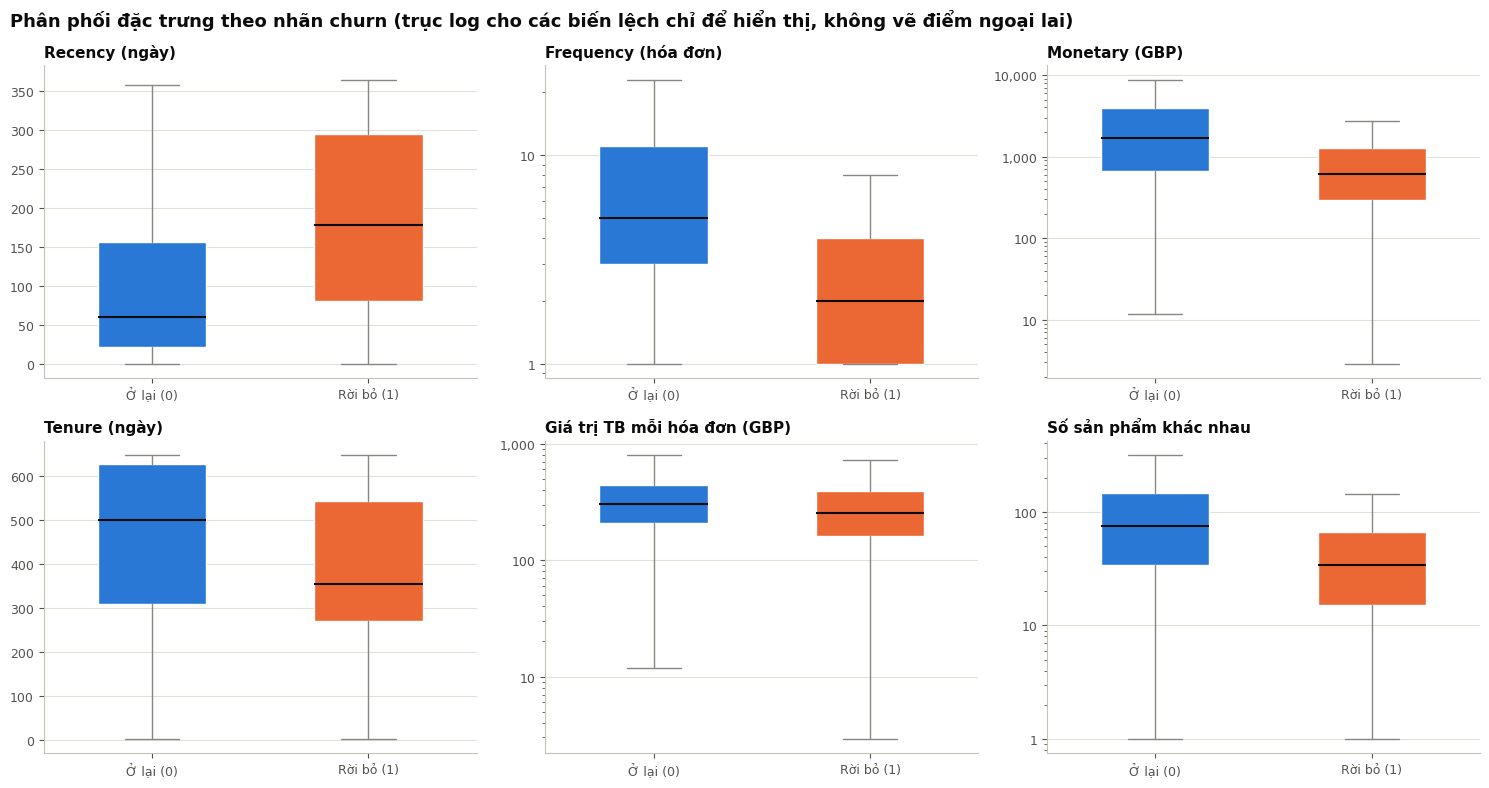

In [5]:
by_churn = data.groupby("churn")[NUM_FEATURES].median().T
by_churn.columns = ["Trung vị: ở lại (0)", "Trung vị: rời bỏ (1)"]
display(by_churn)

uk_churn = data.groupby(data["IsUK"].map({1: "UK", 0: "Khác"}))["churn"].agg(["size", "mean"])
uk_churn.columns = ["Số khách", "Tỷ lệ churn"]
display(uk_churn)

LABELS = {"Recency": "Recency (ngày)", "Frequency": "Frequency (hóa đơn)", "Monetary": "Monetary (GBP)",
          "Tenure": "Tenure (ngày)", "AvgOrderValue": "Giá trị TB mỗi hóa đơn (GBP)",
          "NumProducts": "Số sản phẩm khác nhau"}
LOG_SCALE = ["Frequency", "Monetary", "AvgOrderValue", "NumProducts"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), NUM_FEATURES):
    groups = [data.loc[data["churn"] == c, col] for c in (0, 1)]
    box = ax.boxplot(groups, patch_artist=True, widths=0.5, showfliers=False,
                     medianprops=dict(color=INK, linewidth=1.5),
                     whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
    for patch, c in zip(box["boxes"], (0, 1)):
        patch.set_facecolor(CHURN_COLORS[c])
        patch.set_edgecolor("white")
    ax.set_xticks([1, 2], ["Ở lại (0)", "Rời bỏ (1)"])
    ax.set_title(LABELS[col], fontsize=11)
    if col in LOG_SCALE:
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
fig.suptitle("Phân phối đặc trưng theo nhãn churn (trục log cho các biến lệch chỉ để hiển thị, không vẽ điểm ngoại lai)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "03_dac_trung_theo_churn.png")
plt.show()

**Nhận xét:** - Khách rời bỏ có **Recency cao hơn rõ rệt** (trung vị 179 so với 61 ngày), mua ít lần hơn (2 so với 5 hóa đơn), chi ít hơn (£610 so với £1.676), mua ít loại sản phẩm hơn (34 so với 75) và thâm niên ngắn hơn (355 so với 500 ngày).
- Giá trị trung bình mỗi hóa đơn khác biệt ít (£256 so với £304): khách rời bỏ không hẳn mua đơn nhỏ hơn, mà chủ yếu **mua thưa hơn**.
- Tỷ lệ churn ở Anh (49,5%) và ở các nước khác (46,9%) gần như bằng nhau, nên quốc gia nhiều khả năng không phải yếu tố quan trọng. Mục 2.3 kiểm tra điều này bằng kiểm định Chi-bình phương.
- Các hộp của hai nhóm chồng lấn nhau đáng kể: không một đặc trưng đơn lẻ nào tách được hai nhóm, cần kết hợp nhiều đặc trưng trong mô hình.

### 2.2. Hệ số tương quan Pearson giữa các đặc trưng số (C2)

Hệ số tương quan Pearson giữa hai thuộc tính số A và B (C2):

r(A, B) = Σᵢ (aᵢ - Ā)(bᵢ - B̄) / (n · σ_A · σ_B), với -1 ≤ r ≤ 1.

- r > 0: tương quan thuận (A tăng thì B có xu hướng tăng); r < 0: tương quan nghịch; r ≈ 0: không có tương quan tuyến tính.
- Theo C2, khi |r| rất cao, một thuộc tính gần như suy ra được từ thuộc tính kia, tức là **dư thừa**, và có thể bỏ bớt một thuộc tính.

Đã lưu: figures/03_tuong_quan.png


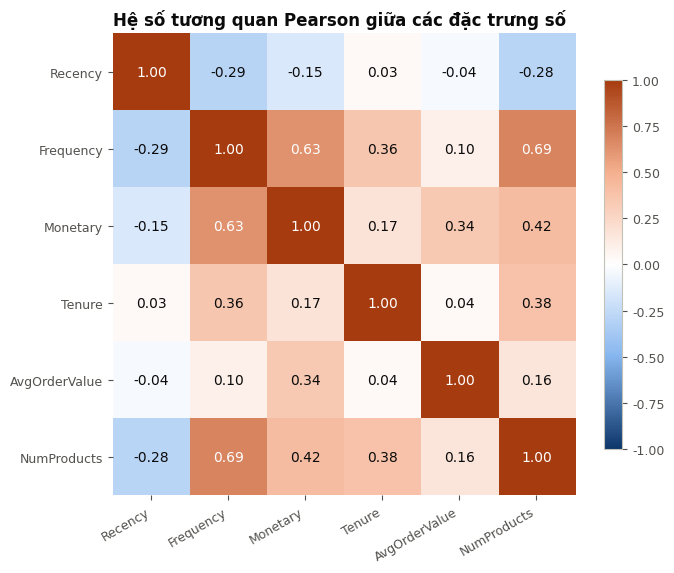

r
Frequency NumProducts   0.687
          Monetary      0.627
Monetary  NumProducts   0.420
Tenure    NumProducts   0.379
Frequency Tenure        0.355
Monetary  AvgOrderValue 0.340

In [6]:
corr = data[NUM_FEATURES].corr(method="pearson")

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr.to_numpy(), cmap=CORR_CMAP, vmin=-1, vmax=1)
for i in range(len(NUM_FEATURES)):
    for j in range(len(NUM_FEATURES)):
        value = corr.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=10,
                color="white" if abs(value) > 0.6 else INK)
ax.set_xticks(range(len(NUM_FEATURES)), NUM_FEATURES, rotation=30, ha="right")
ax.set_yticks(range(len(NUM_FEATURES)), NUM_FEATURES)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("Hệ số tương quan Pearson giữa các đặc trưng số")
fig.colorbar(im, ax=ax, shrink=0.8)
save_fig(fig, "03_tuong_quan.png")
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
upper.reindex(upper.abs().sort_values(ascending=False).index).head(6).rename("r").to_frame()

**Cách đọc:** ô ở hàng A, cột B là hệ số r giữa A và B; màu cam là tương quan thuận, màu xanh là tương quan nghịch, càng đậm thì |r| càng lớn. Bảng bên dưới liệt kê 6 cặp có |r| lớn nhất.

**Nhận xét:** - Cặp tương quan mạnh nhất là **Frequency và NumProducts (r = 0,69)**: khách mua nhiều lần thì cũng mua nhiều loại sản phẩm. Tiếp theo là **Frequency và Monetary (0,63)** và Monetary với NumProducts (0,42). Ba thuộc tính này cùng đo "mức độ gắn bó" của khách.
- Recency tương quan nghịch yếu với Frequency (-0,29) và NumProducts (-0,28): khách mua nhiều thường cũng mua gần đây hơn. Tenure và AvgOrderValue gần như độc lập với Recency.
- **Không cặp nào có |r| vượt 0,8**, nên theo tiêu chí trong C2 chưa có thuộc tính nào dư thừa đến mức phải bỏ. Cả 6 đặc trưng số được giữ lại. Tuy vậy, mức tương quan 0,6 đến 0,7 vẫn vi phạm giả thiết độc lập có điều kiện của Naive Bayes (mục 4).

### 2.3. Kiểm định Chi-bình phương cho thuộc tính rời rạc (C2)

Với hai thuộc tính rời rạc A (c giá trị) và B (r giá trị), kiểm định Chi-bình phương (C2) kiểm tra giả thiết **"A và B độc lập"**:

- Lập **bảng ngẫu nhiên** (*contingency table*): ô (i, j) là số khách quan sát được oᵢⱼ có A = aᵢ và B = bⱼ.
- Tần số kỳ vọng nếu A, B độc lập: eᵢⱼ = (tổng hàng i × tổng cột j) / n.
- χ² = Σ (oᵢⱼ - eᵢⱼ)² / eᵢⱼ, với số bậc tự do (r - 1)(c - 1).
- So sánh χ² với **giá trị tới hạn** ở mức ý nghĩa 0,05 (`chi2.ppf(0.95, df)`): nếu χ² lớn hơn giá trị tới hạn thì bác bỏ giả thiết độc lập, tức hai thuộc tính **phụ thuộc** (có liên hệ với nhau).

Kiểm định cho hai cặp: `IsUK` × `churn` và `ClusterName` × `churn`. Mỗi ô của bảng ghi số quan sát, trong ngoặc là số kỳ vọng.

In [7]:
def chi_square_test(attribute, label, name):
    observed = pd.crosstab(attribute, label)
    chi2_stat, _, dof, expected = chi2_contingency(observed, correction=False)
    critical = chi2.ppf(0.95, dof)
    table = observed.astype(str).copy()
    for i in range(observed.shape[0]):
        for j in range(observed.shape[1]):
            table.iloc[i, j] = f"{observed.iloc[i, j]:,} ({expected[i, j]:,.1f})"
    table.columns = [f"churn = {c}" for c in observed.columns]
    print(f"Bảng ngẫu nhiên {name} × churn (số quan sát, trong ngoặc là số kỳ vọng):")
    display(table)
    return {"Cặp thuộc tính": f"{name} × churn", "χ²": chi2_stat, "Số bậc tự do": dof,
            "Giá trị tới hạn (α = 0,05)": critical,
            "Kết luận": "Phụ thuộc" if chi2_stat > critical else "Độc lập (không bác bỏ được)"}


country = data["IsUK"].map({1: "UK", 0: "Khác"})
cluster_name = pd.Categorical(data["ClusterName"], CLUSTER_ORDER, ordered=True)
chi_results = pd.DataFrame([
    chi_square_test(country, data["churn"], "IsUK"),
    chi_square_test(pd.Series(cluster_name, index=data.index, name="ClusterName"), data["churn"], "ClusterName"),
]).set_index("Cặp thuộc tính")
chi_results.style.format({"χ²": "{:.2f}", "Giá trị tới hạn (α = 0,05)": "{:.3f}"})

Bảng ngẫu nhiên IsUK × churn (số quan sát, trong ngoặc là số kỳ vọng):


,churn = 0,churn = 1
IsUK,,
Khác,204 (195.0),180 (189.0)
UK,"1,979 (1,988.0)","1,936 (1,927.0)"


Bảng ngẫu nhiên ClusterName × churn (số quan sát, trong ngoặc là số kỳ vọng):

,churn = 0,churn = 1
ClusterName,,
VIP,"1,010 (652.0)",274 (632.0)
Khách mới,437 (480.9),510 (466.1)
Có nguy cơ,447 (480.9),500 (466.1)
Ngủ đông,289 (569.2),832 (551.8)


,χ²,Số bậc tự do,"Giá trị tới hạn (α = 0,05)",Kết luận
Cặp thuộc tính,,,,
IsUK × churn,0.93,1,3.841,Độc lập (không bác bỏ được)
ClusterName × churn,692.62,3,7.815,Phụ thuộc


**Nhận xét:** - **`IsUK` và `churn` độc lập:** χ² = 0,93, nhỏ hơn giá trị tới hạn 3,841 (1 bậc tự do, α = 0,05), nên không bác bỏ được giả thiết độc lập. Số quan sát gần như trùng với số kỳ vọng (ví dụ 180 khách ngoài Anh rời bỏ, kỳ vọng 189). Quốc gia không cho thêm thông tin về khả năng rời bỏ.
- **`ClusterName` và `churn` phụ thuộc rất mạnh:** χ² = 692,62, lớn gấp gần 90 lần giá trị tới hạn 7,815 (3 bậc tự do). Chênh lệch lớn nhất nằm ở hai cụm đầu và cuối: VIP chỉ có 274 khách rời bỏ so với 632 nếu độc lập, còn Ngủ đông có 832 so với 552. Nhãn cụm vì vậy là một thuộc tính có ích cho mô hình.
- `IsUK` vẫn được giữ trong mô hình để đối chiếu với độ quan trọng ở mục 6.2, nhưng không kỳ vọng nó đóng góp.

### 2.4. Ma trận đặc trưng

- Mọi đặc trưng số dùng **giá trị gốc**, không biến đổi. Các mô hình cây chỉ so sánh giá trị với ngưỡng nên không bị ảnh hưởng bởi đơn vị hay độ lệch; Gaussian Naive Bayes ước lượng trung bình và độ lệch chuẩn riêng cho từng thuộc tính nên cũng không cần chuẩn hóa.
- `Cluster` dùng trực tiếp số nguyên 0 đến 3. Thứ tự 0 -> 3 đi từ nhóm giá trị cao nhất (VIP) đến thấp nhất (Ngủ đông), nên khi cây quyết định chia ngưỡng trên cột này (ví dụ `Cluster ≤ 1.5`, tức VIP hoặc Khách mới), phép chia vẫn có nghĩa.

In [8]:
FEATURES = NUM_FEATURES + ["IsUK", "Cluster"]
X = data[FEATURES]
y = data["churn"]
print("Các đặc trưng:", FEATURES)
X.head()

Các đặc trưng: ['Recency', 'Frequency', 'Monetary', 'Tenure', 'AvgOrderValue', 'NumProducts', 'IsUK', 'Cluster']


,Recency,Frequency,Monetary,Tenure,AvgOrderValue,NumProducts,IsUK,Cluster
CustomerID,,,,,,,,
12347,39,6,"3,402.390",314,567.065,107,0,0
12348,158,4,"1,388.400",348,347.100,24,0,2
12349,317,2,"2,221.140",499,"1,110.570",89,0,2
12350,220,1,294.400,220,294.400,16,0,3
12351,285,1,300.930,285,300.930,21,0,3


## 3. Chia tập train/test

Chia 80/20 bằng **lấy mẫu phân tầng** (*stratified sampling*, C4) theo `churn` (`stratify=y`), để tỷ lệ churn ở hai tập như nhau. Tập test được giữ riêng, **chỉ dùng một lần** ở bước đánh giá cuối cùng.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {len(X_train):,} khách, tỷ lệ churn = {y_train.mean():.1%}")
print(f"Test:  {len(X_test):,} khách, tỷ lệ churn = {y_test.mean():.1%}")

Train: 3,439 khách, tỷ lệ churn = 49.2%
Test:  860 khách, tỷ lệ churn = 49.2%


**Tiêu chí đánh giá:** độ chính xác (*accuracy*, C4) = số khách được phân lớp đúng / tổng số khách. Accuracy phù hợp với bài toán này vì **hai lớp gần cân bằng** (49,2% churn): mốc so sánh đơn giản nhất là đoán mọi khách thuộc lớp đông hơn (ở lại), chỉ đạt khoảng 50,8%. Một mô hình chỉ có ích khi vượt rõ mốc này.

## 4. Huấn luyện và chọn tham số bằng K-fold cross-validation (C4, C5)

**Quy trình chọn tham số (C4):** dùng **stratified 5-fold cross-validation trên tập train**. Tập train D được chia thành 5 phần D₁, ..., D₅ có tỷ lệ churn như nhau; lần lượt với i = 1..5, mô hình được huấn luyện trên D \ Dᵢ và đo accuracy trên Dᵢ. Accuracy CV là trung bình 5 lần đo. Mỗi tổ hợp tham số được đánh giá bằng vòng lặp tường minh với `cross_val_score(..., scoring="accuracy")`, chọn tổ hợp có accuracy CV trung bình cao nhất. Tập test không tham gia vào bước này.

**Bốn mô hình**, theo thứ tự trong bài giảng:

1. **Decision Tree** (C4). Tiêu chí chọn thuộc tính tách: `gini` (CART, Gini(D) = 1 - Σ pᵢ²) hoặc `entropy` (ID3/C4.5, Info(D) = -Σ pᵢ log₂ pᵢ, chọn thuộc tính có information gain lớn nhất). `max_depth` (độ sâu tối đa) và `min_samples_leaf` (số mẫu tối thiểu ở lá) là **điều kiện dừng** của cây: dừng sớm để cây không học thuộc dữ liệu train, tránh **overfitting**. Lưới thử: `max_depth` ∈ {3, 4, 5, 6, 8}, `min_samples_leaf` ∈ {10, 30, 50}.
2. **Random Forest** (C4, bagging). 300 cây, mỗi cây học trên một **mẫu bootstrap** (lấy mẫu có hoàn lại) của tập train; ở mỗi nút, cây chỉ xét **ngẫu nhiên √m thuộc tính** (`max_features="sqrt"`, m = 8 thuộc tính). Dự đoán cuối cùng là **bỏ phiếu số đông** của các cây. Chọn `min_samples_leaf` ∈ {5, 20}.
3. **AdaBoost** (C4, boosting). 200 learner yếu là cây một tầng, **học tuần tự**: sau mỗi vòng, các mẫu bị phân lớp sai được tăng trọng số để learner tiếp theo tập trung vào chúng. Dự đoán cuối cùng là **bỏ phiếu có trọng số**, learner chính xác hơn có trọng số lớn hơn.
4. **Gaussian Naive Bayes** (C5). Theo định lý Bayes, P(C | X) ∝ P(C) · Π P(xₖ | C), với giả thiết các thuộc tính **độc lập có điều kiện** khi biết lớp C; mỗi P(xₖ | C) là phân phối **Gaussian** với trung bình và độ lệch chuẩn ước lượng từ các khách thuộc lớp C. Ở đây giả thiết độc lập bị vi phạm (Frequency, Monetary và NumProducts tương quan với nhau, mục 2.2) và các biến lệch phải mạnh, không giống phân phối chuẩn, nên Naive Bayes có thể kém hơn các mô hình cây.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

candidates = {
    "Decision Tree": [
        ({"criterion": c, "max_depth": d, "min_samples_leaf": leaf},
         DecisionTreeClassifier(criterion=c, max_depth=d, min_samples_leaf=leaf, random_state=RANDOM_STATE))
        for c in ["gini", "entropy"] for d in [3, 4, 5, 6, 8] for leaf in [10, 30, 50]
    ],
    "Random Forest": [
        ({"n_estimators": 300, "max_features": "sqrt", "min_samples_leaf": leaf},
         RandomForestClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=leaf,
                                random_state=RANDOM_STATE, n_jobs=1))
        for leaf in [5, 20]
    ],
    "AdaBoost": [
        ({"n_estimators": 200}, AdaBoostClassifier(n_estimators=200, random_state=RANDOM_STATE)),
    ],
    "Gaussian NB": [
        ({}, GaussianNB()),
    ],
}

best_models = {}
cv_rows = []
grid_rows = []
for name, options in candidates.items():
    best = None
    for params, model in options:
        scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
        grid_rows.append({"Mô hình": name, **params, "Accuracy CV (TB)": scores.mean()})
        if best is None or scores.mean() > best[2].mean():
            best = (params, model, scores)
    params, model, scores = best
    best_models[name] = model.fit(X_train, y_train)
    cv_rows.append({
        "Mô hình": name,
        "Tham số tốt nhất": params,
        "Accuracy CV (TB)": scores.mean(),
        "Accuracy CV (độ lệch chuẩn)": scores.std(),
    })
    print(f"{name:14s} accuracy CV = {scores.mean():.4f} ± {scores.std():.4f}  {params}")

cv_results = pd.DataFrame(cv_rows).set_index("Mô hình")
cv_results

Decision Tree  accuracy CV = 0.6897 ± 0.0033  {'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 50}


Random Forest  accuracy CV = 0.7031 ± 0.0066  {'n_estimators': 300, 'max_features': 'sqrt', 'min_samples_leaf': 20}


AdaBoost       accuracy CV = 0.6964 ± 0.0076  {'n_estimators': 200}
Gaussian NB    accuracy CV = 0.6298 ± 0.0118  {}


,Tham số tốt nhất,Accuracy CV (TB),Accuracy CV (độ lệch chuẩn)
Mô hình,,,
Decision Tree,"{'criterion': 'gini', 'max_depth': 6, 'min_sam...",0.690,0.003
Random Forest,"{'n_estimators': 300, 'max_features': 'sqrt', ...",0.703,0.007
AdaBoost,{'n_estimators': 200},0.696,0.008
Gaussian NB,{},0.630,0.012


In [11]:
tree_grid = pd.DataFrame([row for row in grid_rows if row["Mô hình"] == "Decision Tree"])
tree_grid.pivot_table(index="max_depth", columns=["criterion", "min_samples_leaf"], values="Accuracy CV (TB)") \
    .style.format("{:.3f}").highlight_max(axis=None, color="#cde2fb")

**Cách đọc:** bảng đầu là kết quả tốt nhất của mỗi mô hình (accuracy CV trung bình và độ lệch chuẩn giữa 5 fold). Bảng thứ hai là accuracy CV của cả 30 tổ hợp điều kiện dừng của cây quyết định: hàng là độ sâu tối đa, cột là tiêu chí tách và số mẫu tối thiểu ở lá.

**Nhận xét:** - **Random Forest có accuracy CV cao nhất (0,703 ± 0,007)**, tiếp theo là AdaBoost (0,696) và Decision Tree (0,690). Gaussian Naive Bayes thấp nhất (0,630), đúng như dự đoán vì giả thiết độc lập có điều kiện và phân phối Gaussian đều không thỏa.
- **Điều kiện dừng của cây:** cây quá nông (độ sâu 3) chỉ đạt khoảng 0,66 vì chưa đủ điều kiện để phân biệt (*underfitting*). Accuracy tăng dần đến **độ sâu 6** (tốt nhất 0,690 với Gini, `min_samples_leaf=50`), rồi **giảm khi độ sâu 8** (0,664 đến 0,682). Ở độ sâu 8, lá càng nhỏ thì càng kém (Gini: 0,669 với 10 mẫu ở lá so với 0,682 với 50 mẫu): cây sâu với lá nhỏ học cả nhiễu của tập train, tức là **overfitting**.
- Gini và entropy cho kết quả gần nhau (chênh dưới 0,01 ở mọi độ sâu), Gini nhỉnh hơn ở độ sâu 6.
- Hai mô hình ensemble (Random Forest, AdaBoost) tốt hơn một cây đơn lẻ khoảng 0,6 đến 1,3 điểm phần trăm: kết hợp nhiều cây giúp giảm phương sai (*variance*) của một cây duy nhất (C4).

## 5. Đánh giá trên tập test

Mỗi mô hình (đã huấn luyện lại trên toàn bộ tập train với tham số tốt nhất) dự đoán cho 860 khách của tập test. **Accuracy test** là tỷ lệ khách được dự đoán đúng nhãn. Mô hình được chọn theo accuracy CV, còn tập test chỉ dùng để báo cáo kết quả cuối cùng.

In [12]:
test_proba = {}
test_pred = {}
for name, model in best_models.items():
    test_proba[name] = model.predict_proba(X_test)[:, 1]
    test_pred[name] = model.predict(X_test)

comparison = cv_results[["Accuracy CV (TB)", "Accuracy CV (độ lệch chuẩn)"]].copy()
comparison["Accuracy test"] = pd.Series({name: accuracy_score(y_test, pred) for name, pred in test_pred.items()})
majority_rate = 1 - y_train.mean()
print(f"Mốc so sánh (đoán mọi khách là ở lại): accuracy = {majority_rate:.3f} trên train, {1 - y_test.mean():.3f} trên test")
comparison.style.format("{:.3f}")

Mốc so sánh (đoán mọi khách là ở lại): accuracy = 0.508 trên train, 0.508 trên test


,Accuracy CV (TB),Accuracy CV (độ lệch chuẩn),Accuracy test
Mô hình,,,
Decision Tree,0.690,0.003,0.658
Random Forest,0.703,0.007,0.678
AdaBoost,0.696,0.008,0.664
Gaussian NB,0.630,0.012,0.608


In [13]:
best_name = cv_results["Accuracy CV (TB)"].idxmax()
best_model = best_models[best_name]
print(f"Mô hình được chọn (accuracy CV cao nhất): {best_name}")

Mô hình được chọn (accuracy CV cao nhất): Random Forest


**Lưu ý phương pháp:** mô hình tốt nhất được chọn theo **accuracy trung bình trên cross-validation**, không theo kết quả trên tập test. Nếu chọn theo tập test, tập test sẽ gián tiếp tham gia vào quá trình chọn mô hình và kết quả báo cáo sẽ lạc quan hơn thực tế.

### 5.1. Accuracy trên tập test theo từng cụm

Bảng cho biết mỗi mô hình dự đoán đúng bao nhiêu phần trăm khách của từng cụm trong tập test. Cột `Accuracy nếu đoán theo lớp đông hơn` là mốc so sánh trong cụm: đoán mọi khách của cụm cùng một nhãn (nhãn chiếm đa số trong cụm).

In [14]:
test_cluster = data.loc[X_test.index, "ClusterName"]
by_cluster = pd.DataFrame({
    name: pd.Series(pred == y_test.to_numpy(), index=X_test.index).groupby(test_cluster).mean()
    for name, pred in test_pred.items()
})
cluster_churn = y_test.groupby(test_cluster).mean()
by_cluster.insert(0, "Số khách (test)", test_cluster.value_counts())
by_cluster.insert(1, "Tỷ lệ churn (test)", cluster_churn)
by_cluster.insert(2, "Accuracy nếu đoán theo lớp đông hơn", np.maximum(cluster_churn, 1 - cluster_churn))
by_cluster = by_cluster.reindex(CLUSTER_ORDER)
by_cluster.style.format({col: "{:,.0f}" if col == "Số khách (test)" else "{:.1%}" if col == "Tỷ lệ churn (test)"
                         else "{:.3f}" for col in by_cluster.columns})

,Số khách (test),Tỷ lệ churn (test),Accuracy nếu đoán theo lớp đông hơn,Decision Tree,Random Forest,AdaBoost,Gaussian NB
ClusterName,,,,,,,
VIP,257,24.1%,0.759,0.767,0.770,0.767,0.669
Khách mới,195,51.8%,0.518,0.585,0.636,0.590,0.518
Có nguy cơ,192,56.2%,0.562,0.536,0.568,0.557,0.510
Ngủ đông,216,70.4%,0.704,0.704,0.704,0.704,0.704


### 5.2. So sánh 4 mô hình

Đã lưu: figures/03_so_sanh_mo_hinh.png

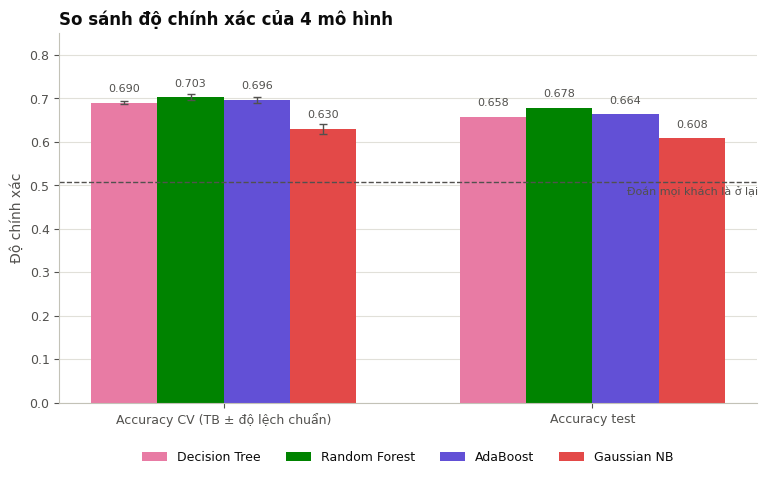

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.8))
groups = ["Accuracy CV", "Accuracy test"]
w = 0.18
for k, name in enumerate(comparison.index):
    offset = (k - 1.5) * w
    ax.bar(0 + offset, comparison.loc[name, "Accuracy CV (TB)"], width=w, color=MODEL_COLORS[name], label=name,
           yerr=comparison.loc[name, "Accuracy CV (độ lệch chuẩn)"], error_kw=dict(ecolor=INK_2, lw=1, capsize=3))
    ax.bar(1 + offset, comparison.loc[name, "Accuracy test"], width=w, color=MODEL_COLORS[name])
    for xpos, value in [(0 + offset, comparison.loc[name, "Accuracy CV (TB)"]),
                        (1 + offset, comparison.loc[name, "Accuracy test"])]:
        ax.text(xpos, value + 0.02, f"{value:.3f}", ha="center", va="bottom", fontsize=8, color=INK_2)
ax.axhline(majority_rate, color=INK_2, linewidth=1, linestyle="--")
ax.text(1.45, majority_rate - 0.01, "Đoán mọi khách là ở lại", ha="right", va="top", fontsize=8, color=INK_2)
ax.set_xticks([0, 1], ["Accuracy CV (TB ± độ lệch chuẩn)", "Accuracy test"])
ax.set_ylim(0, 0.85)
ax.set_ylabel("Độ chính xác")
ax.set_title("So sánh độ chính xác của 4 mô hình")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4)
save_fig(fig, "03_so_sanh_mo_hinh.png")
plt.show()

**Nhận xét kết quả các mô hình:** - Cả 4 mô hình đều vượt rõ mốc so sánh 0,508 (đoán mọi khách là ở lại). Trên tập test: **Random Forest 0,678**, AdaBoost 0,664, Decision Tree 0,658, Gaussian NB 0,608. Thứ tự trên test giống hệt thứ tự trên CV, nên lựa chọn Random Forest theo CV được tập test xác nhận.
- Accuracy test thấp hơn accuracy CV khoảng 2 đến 3 điểm phần trăm ở **cả 4 mô hình**, kể cả Naive Bayes vốn rất đơn giản và khó overfitting. Nguyên nhân chủ yếu là dao động do mẫu: tập test chỉ có 860 khách. Có thể kết luận độ chính xác thực tế của mô hình nằm trong khoảng 0,68 đến 0,70: khoảng 7 trên 10 khách được dự đoán đúng.
- **Theo từng cụm**, mô hình chỉ hơn cách "đoán theo lớp đông hơn của cụm" một chút: VIP 0,770 so với 0,759; Có nguy cơ 0,568 so với 0,562; ở Ngủ đông, cả 4 mô hình đều dự đoán gần như mọi khách rời bỏ nên accuracy bằng đúng mốc 0,704. Riêng **Khách mới** là nơi Random Forest hơn rõ (0,636 so với 0,518). Nói cách khác, phần lớn độ chính xác đến từ việc biết khách thuộc cụm nào; phân biệt từng khách bên trong cụm khó hơn nhiều.
- Mức accuracy khoảng 0,7 là **khá**, phù hợp với độ khó của bài toán: khách sỉ mua hàng không đều đặn, và mô hình chỉ có lịch sử giao dịch, không có thông tin như khiếu nại, giá của đối thủ hay tình hình kinh doanh của khách.

## 6. Giải thích mô hình

### 6.1. Cây quyết định -> tập luật (C4)

Mỗi đường đi từ gốc đến một lá của cây quyết định là một luật "nếu ... thì ..." (C4, chuyển cây thành tập luật): các điều kiện trên đường đi nối với nhau bằng "và", vế "thì" là lớp chiếm đa số ở lá. Cây được dùng là cây tốt nhất ở mục 4, huấn luyện trên giá trị gốc nên ngưỡng đọc được trực tiếp (ví dụ "Recency > 120 ngày").

Hình vẽ 3 tầng đầu của cây. Mỗi ô ghi: điều kiện tách, `samples` = tỷ lệ khách (trong tập train) rơi vào ô, `value` = [tỷ lệ ở lại, tỷ lệ rời bỏ], `class` = lớp chiếm đa số. Sau hình là toàn bộ tập luật (`export_text`) và bảng luật của từng lá.

Đã lưu: figures/03_cay_quyet_dinh.png


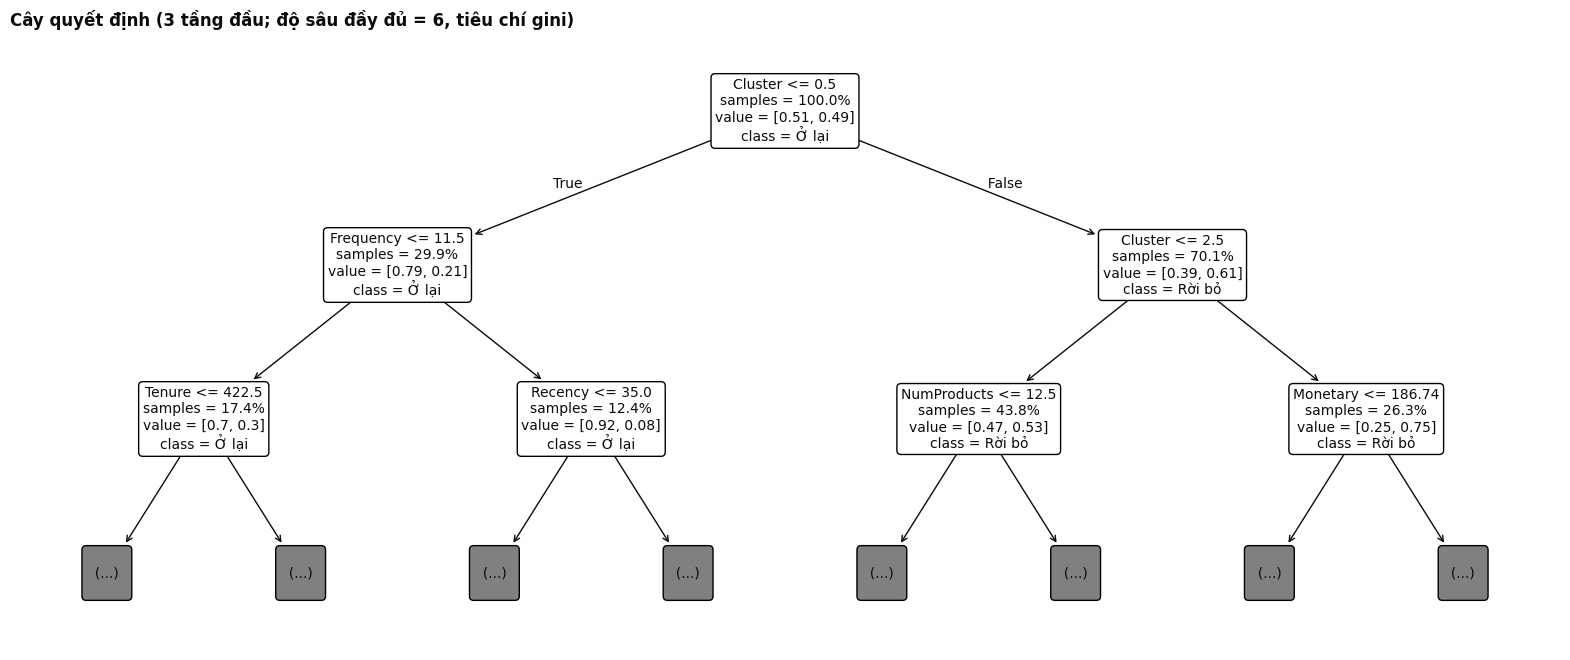

|--- Cluster <= 0
|   |--- Frequency <= 12
|   |   |--- Tenure <= 422
|   |   |   |--- NumProducts <= 102
|   |   |   |   |--- weights: [77, 20] class: 0
|   |   |   |--- NumProducts >  102
|   |   |   |   |--- weights: [64, 6] class: 0
|   |   |--- Tenure >  422
|   |   |   |--- Monetary <= 2446
|   |   |   |   |--- AvgOrderValue <= 305
|   |   |   |   |   |--- Tenure <= 572
|   |   |   |   |   |   |--- weights: [25, 30] class: 1
|   |   |   |   |   |--- Tenure >  572
|   |   |   |   |   |   |--- weights: [44, 22] class: 0
|   |   |   |   |--- AvgOrderValue >  305
|   |   |   |   |   |--- weights: [19, 36] class: 1
|   |   |   |--- Monetary >  2446
|   |   |   |   |--- Frequency <= 8
|   |   |   |   |   |--- weights: [55, 31] class: 0
|   |   |   |   |--- Frequency >  8
|   |   |   |   |   |--- Tenure <= 612
|   |   |   |   |   |   |--- weights: [81, 25] class: 0
|   |   |   |   |   |--- Tenure >  612
|   |   |   |   |   |   |--- weights: [58, 7] class: 0
|   |--- Frequency >  12
|   

In [16]:
tree = best_models["Decision Tree"]

fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(tree, max_depth=2, feature_names=FEATURES, class_names=["Ở lại", "Rời bỏ"],
          filled=False, rounded=True, proportion=True, impurity=False, precision=2, fontsize=10, ax=ax)
ax.set_title(f"Cây quyết định (3 tầng đầu; độ sâu đầy đủ = {tree.get_depth()}, tiêu chí {tree.criterion})")
save_fig(fig, "03_cay_quyet_dinh.png")
plt.show()

print(export_text(tree, feature_names=FEATURES, show_weights=True, decimals=0))

In [17]:
def describe_range(feature, low, high):
    if feature == "Cluster":
        names = [name for code, name in enumerate(CLUSTER_ORDER) if low < code <= high]
        return "cụm " + " hoặc ".join(names)
    if np.isfinite(low) and np.isfinite(high):
        return f"{feature} > {low:,.0f} và ≤ {high:,.0f}"
    return f"{feature} > {low:,.0f}" if np.isfinite(low) else f"{feature} ≤ {high:,.0f}"


def leaf_rules(model, feature_names):
    t = model.tree_
    rules = {}

    def walk(node, low, high):
        if t.children_left[node] == -1:
            used = [f for f in feature_names if f in low or f in high]
            rules[node] = " và ".join(describe_range(f, low.get(f, -np.inf), high.get(f, np.inf)) for f in used)
            return
        f, thr = feature_names[t.feature[node]], t.threshold[node]
        walk(t.children_left[node], low, {**high, f: min(thr, high.get(f, np.inf))})
        walk(t.children_right[node], {**low, f: max(thr, low.get(f, -np.inf))}, high)

    walk(0, {}, {})
    return rules


rules_text = leaf_rules(tree, FEATURES)
leaf_of = pd.Series(tree.apply(X_train), index=X_train.index)
leaf_table = y_train.groupby(leaf_of).agg(["size", "mean"])
leaf_table.columns = ["Số khách (train)", "Tỷ lệ rời bỏ"]
leaf_table.insert(0, "Luật (nếu ...)", leaf_table.index.map(rules_text))
leaf_table["Thì"] = np.where(leaf_table["Tỷ lệ rời bỏ"] >= 0.5, "Rời bỏ", "Ở lại")
leaf_table = leaf_table.sort_values("Tỷ lệ rời bỏ", ascending=False).reset_index(drop=True)
leaf_table.style.format({"Tỷ lệ rời bỏ": "{:.1%}"}).set_properties(subset=["Luật (nếu ...)"], **{"text-align": "left"})

,Luật (nếu ...),Số khách (train),Tỷ lệ rời bỏ,Thì
0,Recency > 232 và Monetary ≤ 187 và Tenure ≤ 320 và cụm Ngủ đông,76,94.7%,Rời bỏ
1,Monetary > 187 và Tenure ≤ 292 và AvgOrderValue > 304 và cụm Ngủ đông,90,87.8%,Rời bỏ
2,Recency ≤ 232 và Monetary ≤ 187 và Tenure ≤ 320 và cụm Ngủ đông,55,87.3%,Rời bỏ
3,Recency > 48 và NumProducts ≤ 6 và cụm Khách mới hoặc Có nguy cơ,73,84.9%,Rời bỏ
4,Monetary ≤ 187 và Tenure > 320 và cụm Ngủ đông,57,84.2%,Rời bỏ
5,Monetary > 187 và ≤ 517 và Tenure > 292 và AvgOrderValue > 304 và cụm Ngủ đông,69,79.7%,Rời bỏ
6,Monetary > 293 và ≤ 505 và AvgOrderValue ≤ 304 và cụm Ngủ đông,153,75.2%,Rời bỏ
7,Recency > 48 và NumProducts > 6 và ≤ 12 và cụm Khách mới hoặc Có nguy cơ,76,69.7%,Rời bỏ
8,"Recency > 128 và Monetary ≤ 1,628 và NumProducts > 12 và ≤ 108 và cụm Khách mới hoặc Có nguy cơ",310,69.7%,Rời bỏ
9,Monetary > 517 và Tenure > 292 và AvgOrderValue > 304 và cụm Ngủ đông,135,68.1%,Rời bỏ


**Cách đọc bảng luật:** mỗi dòng là một lá của cây (35 lá). Cột `Luật (nếu ...)` là các điều kiện trên đường đi từ gốc đến lá, đã gộp các điều kiện trên cùng một thuộc tính; `Thì` là lớp chiếm đa số ở lá. Bảng được xếp theo tỷ lệ rời bỏ giảm dần.

**Nhận xét:** - **Điều kiện tách đầu tiên là nhãn cụm**: `Cluster ≤ 0.5` tách VIP (30% khách train, tỷ lệ rời bỏ 21%) khỏi phần còn lại (61%); tầng thứ hai tách tiếp Ngủ đông (75%) khỏi Khách mới và Có nguy cơ (53%). Cây dùng nhãn cụm như một bản tóm tắt R, F, M, rồi mới tinh chỉnh bằng các đặc trưng khác bên trong từng nhóm.
- **Ngưỡng Recency khoảng 4 tháng vẫn xuất hiện** ở nhóm Khách mới và Có nguy cơ: khách mua từ 13 đến 108 loại sản phẩm, chi không quá £1.628 và đã **hơn 128 ngày** không mua có tỷ lệ rời bỏ **69,7%** (310 khách, lá lớn thứ hai). Cùng nhóm nhưng mua trong vòng 128 ngày thì tỷ lệ rời bỏ chỉ 41,8% (378 khách), hoặc 20,2% nếu đã mua trên 4 hóa đơn và chi trên £1.242.
- **Khách Ngủ đông chi rất ít** (Monetary ≤ £187), thâm niên dưới 320 ngày và đã hơn 232 ngày không mua: tỷ lệ rời bỏ **94,7%** (76 khách). Gần như mọi lá của Ngủ đông đều là "Rời bỏ".
- **VIP còn mua đều:** mua trên 14 hóa đơn và lần cuối trong vòng 18 ngày thì gần như không rời bỏ (0% và 2,3%, 175 khách). Ngược lại, VIP có thâm niên trên 422 ngày nhưng mua không quá 12 lần, chi không quá £2.446 và có giá trị đơn trung bình trên £305 rời bỏ tới 65,5% (55 khách): đây là kiểu VIP mua lô lớn nhưng thưa.
- Quy tắc thực hành cho bộ phận kinh doanh: **khoảng 4 tháng không phát sinh đơn hàng là thời điểm nên chủ động liên hệ khách**, đặc biệt với các khách từng mua thường xuyên.

### 6.2. Độ quan trọng của đặc trưng theo mức giảm Gini (C4)

Ở mỗi nút, cây chọn thuộc tính làm **giảm độ không thuần khiết Gini** nhiều nhất (C4, CART):

ΔGini(A) = Gini(D) - Σⱼ (|Dⱼ| / |D|) · Gini(Dⱼ), với Gini(D) = 1 - Σᵢ pᵢ².

Độ quan trọng của một thuộc tính (`feature_importances_`) là **tổng mức giảm Gini**, có trọng số theo số mẫu đi qua nút, tại mọi nút dùng thuộc tính đó; với Random Forest, lấy trung bình trên tất cả các cây. Kết quả được chuẩn hóa để tổng bằng 1.

Độ quan trọng được lấy từ mô hình được chọn nếu đó là cây quyết định hoặc Random Forest. Nếu mô hình được chọn là AdaBoost hoặc Naive Bayes, dùng Random Forest thay thế (ô code ghi rõ mô hình được dùng).

Độ quan trọng lấy từ mô hình được chọn: Random Forest
Đã lưu: figures/03_feature_importance.png


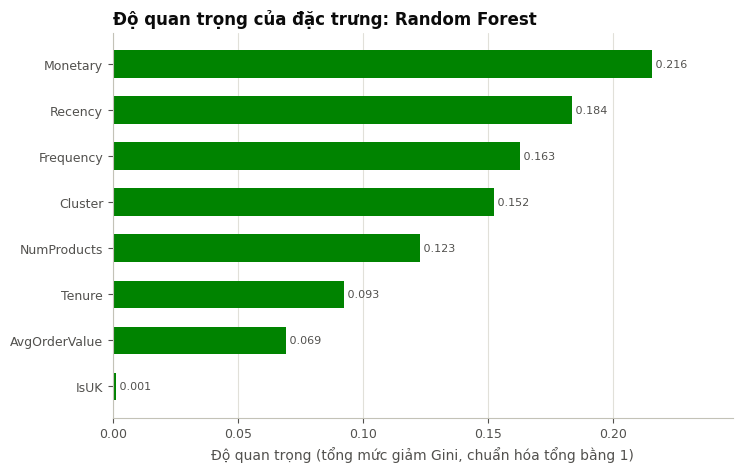

,Độ quan trọng
Monetary,0.216
Recency,0.184
Frequency,0.163
Cluster,0.152
NumProducts,0.123
Tenure,0.093
AvgOrderValue,0.069
IsUK,0.001


In [18]:
importance_name = best_name if best_name in ("Decision Tree", "Random Forest") else "Random Forest"
importance_model = best_models[importance_name]
if importance_name == best_name:
    print(f"Độ quan trọng lấy từ mô hình được chọn: {importance_name}")
else:
    print(f"Mô hình được chọn là {best_name}; độ quan trọng lấy từ Random Forest")
importance = pd.Series(importance_model.feature_importances_, index=FEATURES, name="Độ quan trọng")

plot_data = importance.sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(plot_data.index, plot_data.values, height=0.6, color=MODEL_COLORS[importance_name])
for yy, v in enumerate(plot_data.values):
    ax.text(v, yy, f" {v:.3f}", va="center", fontsize=8, color=INK_2)
ax.set_xlabel("Độ quan trọng (tổng mức giảm Gini, chuẩn hóa tổng bằng 1)")
ax.set_xlim(0, plot_data.max() * 1.15)
ax.set_title(f"Độ quan trọng của đặc trưng: {importance_name}")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
save_fig(fig, "03_feature_importance.png")
plt.show()
importance.sort_values(ascending=False).to_frame()

**Cách đọc:** mỗi thanh là phần đóng góp của một đặc trưng vào tổng mức giảm Gini của 300 cây trong Random Forest (tổng các thanh bằng 1).

**Nhận xét về các yếu tố khiến khách rời bỏ:** 1. **Monetary (0,216), Recency (0,184) và Frequency (0,163)** là ba đặc trưng quan trọng nhất, cộng lại chiếm khoảng 56% tổng mức giảm Gini. Đây đúng là ba chỉ số RFM.
2. **Nhãn cụm (0,152)** đứng thứ tư. Khác với cách mã hóa one-hot trước đây (mỗi cột chỉ nói "có thuộc cụm này không"), cột `Cluster` dạng số nguyên cho phép cây chia "VIP với phần còn lại" hoặc "Ngủ đông với phần còn lại" chỉ bằng một ngưỡng, nên được dùng nhiều. Kiểm định Chi-bình phương ở mục 2.3 cũng cho thấy nhãn cụm phụ thuộc rất mạnh vào `churn`.
3. **NumProducts (0,123) và Tenure (0,093)** đóng góp vừa phải; NumProducts tương quan cao với Frequency (r = 0,69) nên hai biến "chia nhau" mức quan trọng.
4. **IsUK gần như bằng 0 (0,001)**, khớp với kết luận độc lập của kiểm định Chi-bình phương.
5. Lưu ý khi đọc: độ quan trọng theo mức giảm Gini ưu ái các thuộc tính có **nhiều giá trị khác nhau** (như Monetary, có hàng nghìn ngưỡng chia có thể), giống như information gain ưu ái thuộc tính nhiều giá trị (lý do C4.5 dùng gain ratio). Vì vậy thứ tự giữa Monetary, Recency và Frequency chỉ nên hiểu là "ba yếu tố hàng đầu", còn cây quyết định ở mục 6.1 cho thấy Recency là ngưỡng hành động dễ dùng nhất.

## 7. Dự đoán cho toàn bộ khách hàng và nguy cơ theo cụm

Notebook 04 cần xác suất churn của **tất cả** khách hàng để chọn khách cần gợi ý sản phẩm. Nếu dùng mô hình đã huấn luyện trên tập train để dự đoán lại chính tập train, xác suất sẽ "đẹp" hơn thực tế (mô hình đã thấy các khách đó). Vì vậy:

- Với khách thuộc **tập train**: dùng `cross_val_predict` với đúng 5 fold ở mục 4, theo cách của K-fold cross-validation (C4). Tập train D được chia thành D₁, ..., D₅; với mỗi i, mô hình được huấn luyện trên D \ Dᵢ rồi dự đoán cho các khách thuộc Dᵢ. Như vậy mỗi khách được dự đoán bởi một mô hình **không chứa fold của khách đó**.
- Với khách thuộc **tập test**: dùng `predict_proba` của mô hình được chọn, đã huấn luyện trên toàn bộ tập train.

**Xác suất churn của Random Forest:** mỗi cây cho tỷ lệ khách rời bỏ ở lá mà khách rơi vào; xác suất churn là trung bình của 300 cây, tức là **tỷ lệ phiếu** của các cây cho lớp "rời bỏ". Khách được dự đoán rời bỏ khi tỷ lệ phiếu này từ 0,5 trở lên (bỏ phiếu số đông).

In [19]:
oof_proba = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
test_proba_best = test_proba[best_name]

predictions = pd.concat([
    pd.DataFrame({"CustomerID": X_train.index, "Set": "train", "churn_proba": oof_proba}),
    pd.DataFrame({"CustomerID": X_test.index, "Set": "test", "churn_proba": test_proba_best}),
], ignore_index=True)
predictions["churn_pred"] = (predictions["churn_proba"] >= 0.5).astype(int)
predictions = predictions.merge(data[["ClusterName", "churn"]], left_on="CustomerID", right_index=True)

print(f"Accuracy out-of-fold trên tập train: {accuracy_score(y_train, (oof_proba >= 0.5).astype(int)):.3f}")
print(f"Accuracy trên tập test:              {accuracy_score(y_test, (test_proba_best >= 0.5).astype(int)):.3f}")

Accuracy out-of-fold trên tập train: 0.703
Accuracy trên tập test:              0.678


In [20]:
risk_by_cluster = predictions.groupby("ClusterName").agg(
    NumCustomers=("CustomerID", "size"),
    ActualChurnRate=("churn", "mean"),
    MeanChurnProba=("churn_proba", "mean"),
    PredictedChurners=("churn_pred", "sum"),
).reindex(CLUSTER_ORDER)
risk_by_cluster["PredictedChurnRate"] = risk_by_cluster["PredictedChurners"] / risk_by_cluster["NumCustomers"]

test_part = predictions[predictions["Set"] == "test"]
top_quarter = test_part[test_part["churn_proba"]
                        >= test_part.groupby("ClusterName")["churn_proba"].transform(lambda s: s.quantile(0.75))]
risk_by_cluster["TestChurnRate"] = test_part.groupby("ClusterName")["churn"].mean()
risk_by_cluster["TopQuarterChurnRate"] = top_quarter.groupby("ClusterName")["churn"].mean()

risk_by_cluster.rename(columns={
    "NumCustomers": "Số khách", "ActualChurnRate": "Tỷ lệ churn thực tế", "MeanChurnProba": "Xác suất churn TB",
    "PredictedChurners": "Số khách dự đoán rời bỏ", "PredictedChurnRate": "Tỷ lệ dự đoán rời bỏ",
    "TestChurnRate": "Tỷ lệ churn chung của cụm (tập test)",
    "TopQuarterChurnRate": "Tỷ lệ churn thực tế của 25% khách có xác suất cao nhất trong cụm (tập test)",
}).style.format({
    "Số khách": "{:,}", "Số khách dự đoán rời bỏ": "{:,}", "Tỷ lệ churn thực tế": "{:.1%}",
    "Xác suất churn TB": "{:.3f}", "Tỷ lệ dự đoán rời bỏ": "{:.1%}", "Tỷ lệ churn chung của cụm (tập test)": "{:.1%}",
    "Tỷ lệ churn thực tế của 25% khách có xác suất cao nhất trong cụm (tập test)": "{:.1%}",
})

,Số khách,Tỷ lệ churn thực tế,Xác suất churn TB,Số khách dự đoán rời bỏ,Tỷ lệ dự đoán rời bỏ,Tỷ lệ churn chung của cụm (tập test),Tỷ lệ churn thực tế của 25% khách có xác suất cao nhất trong cụm (tập test)
ClusterName,,,,,,,
VIP,"1,284",21.3%,0.210,17,1.3%,24.1%,47.7%
Khách mới,947,53.9%,0.537,546,57.7%,51.8%,57.1%
Có nguy cơ,947,52.8%,0.518,519,54.8%,56.2%,72.9%
Ngủ đông,"1,121",74.2%,0.750,"1,120",99.9%,70.4%,75.9%


Đã lưu: figures/03_xac_suat_churn_theo_cum.png


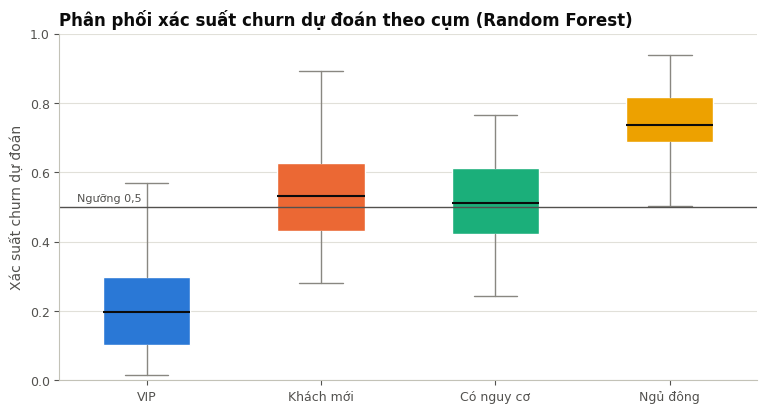

In [21]:
fig, ax = plt.subplots(figsize=(9, 4.5))
groups = [predictions.loc[predictions["ClusterName"] == name, "churn_proba"] for name in CLUSTER_ORDER]
box = ax.boxplot(groups, patch_artist=True, widths=0.5, showfliers=False,
                 medianprops=dict(color=INK, linewidth=1.5),
                 whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
for patch, name in zip(box["boxes"], CLUSTER_ORDER):
    patch.set_facecolor(CLUSTER_COLORS[name])
    patch.set_edgecolor("white")
ax.axhline(0.5, color=INK_2, linewidth=1)
ax.text(0.6, 0.51, "Ngưỡng 0,5", ha="left", va="bottom", fontsize=8, color=INK_2)
ax.set_xticks(range(1, 5), CLUSTER_ORDER)
ax.set_ylim(0, 1)
ax.set_ylabel("Xác suất churn dự đoán")
ax.set_title(f"Phân phối xác suất churn dự đoán theo cụm ({best_name})")
save_fig(fig, "03_xac_suat_churn_theo_cum.png")
plt.show()

**Cách đọc:** hai cột cuối chỉ tính trên tập test. So sánh hai cột này cho biết mô hình **xếp hạng** khách bên trong cụm có hiệu quả không: nếu 25% khách được mô hình cho xác suất cao nhất thực sự rời bỏ nhiều hơn hẳn mức chung của cụm, thì chọn khách theo thứ hạng trong cụm là đáng tin.

**Nhận xét về nguy cơ theo cụm:** - Accuracy out-of-fold trên tập train là 0,703 và trên tập test là 0,678, khớp với kết quả ở mục 4 và 5.
- Xác suất churn trung bình theo cụm **khớp rất sát** tỷ lệ thực tế (VIP 0,210 so với 21,3%; Khách mới 0,537 so với 53,9%; Có nguy cơ 0,518 so với 52,8%; Ngủ đông 0,750 so với 74,2%).
- **Ngủ đông là cụm có nguy cơ cao nhất**: 99,9% khách bị dự đoán rời bỏ ở ngưỡng 0,5. Nhưng 25% khách có xác suất cao nhất chỉ rời bỏ 75,9%, gần bằng mức chung 70,4% của cụm (tập test): mô hình gần như không phân biệt được khách ngủ đông nào sẽ quay lại.
- **Có nguy cơ** là nơi xếp hạng hiệu quả nhất trong ba cụm nguy cơ: 25% khách có xác suất cao nhất rời bỏ 72,9%, so với 56,2% của cả cụm. Ở **Khách mới**, chênh lệch nhỏ hơn (57,1% so với 51,8%).
- **VIP**: ngưỡng 0,5 chỉ cảnh báo được **17 khách** (1,3%), trong khi thực tế 21% khách VIP (274 khách) đã rời bỏ. Nhưng 25% khách VIP có xác suất cao nhất rời bỏ **47,7%, gần gấp đôi** mức chung 24,1% của VIP trên tập test: mô hình **xếp hạng** được các VIP theo nguy cơ, chỉ là xác suất tuyệt đối của họ đều thấp.
- Mỗi nhóm 25% trên tập test chỉ có khoảng 50 đến 65 khách, nên các tỷ lệ này cần được hiểu thận trọng.
- **Hệ quả cho notebook 04:** dùng một ngưỡng chung 0,5 sẽ bỏ qua gần như toàn bộ VIP (nhóm mang lại 77% doanh thu) và dồn hết vào khách Ngủ đông có giá trị thấp. Vì vậy ở notebook 04, "khách có nguy cơ cao" sẽ được chọn **theo thứ hạng trong từng cụm**: nhóm 25% khách có xác suất churn cao nhất của mỗi cụm (phân vị 75%, C2).

## 8. Xuất kết quả dự đoán

Các cột: `CustomerID`, `ClusterName`, `churn_proba` (xác suất churn dự đoán), `churn_pred` (nhãn dự đoán với ngưỡng 0,5), kèm `churn` (nhãn thực tế) và `Set` (khách thuộc tập train hay test) để tiện kiểm tra.

In [22]:
predictions = predictions[["CustomerID", "ClusterName", "churn_proba", "churn_pred", "churn", "Set"]]
predictions = predictions.sort_values("churn_proba", ascending=False)
predictions.to_csv(PROCESSED_DIR / "churn_predictions.csv", index=False, encoding="utf-8-sig")
print(predictions.shape)
predictions.head()

(4299, 6)


,CustomerID,ClusterName,churn_proba,churn_pred,churn,Set
2971,13303,Ngủ đông,0.939,1,1,train
2746,13068,Ngủ đông,0.938,1,0,train
2520,15158,Ngủ đông,0.938,1,0,train
689,14520,Ngủ đông,0.932,1,0,train
2122,14589,Ngủ đông,0.932,1,1,train


## 9. Tóm tắt

| Nội dung | Kết quả |
|---|---|
| Đặc trưng | Recency, Frequency, Monetary, Tenure, AvgOrderValue, NumProducts, IsUK, Cluster (số nguyên 0 đến 3); giá trị gốc, chỉ tính từ giai đoạn quan sát |
| Tương quan và kiểm định (C2) | Cao nhất Frequency và NumProducts (r = 0,69), không cặp nào vượt 0,8. Chi-bình phương: `IsUK` độc lập với churn (χ² = 0,93), nhãn cụm phụ thuộc churn (χ² = 692,6) |
| Dữ liệu | 4.299 khách, churn 49,2% (gần cân bằng, nên dùng accuracy); train 3.439 / test 860, lấy mẫu phân tầng |
| Mô hình được chọn | Random Forest (300 cây, √m thuộc tính mỗi nút, `min_samples_leaf=20`), accuracy CV 0,703 ± 0,007 |
| Kết quả test | Random Forest 0,678; AdaBoost 0,664; Decision Tree 0,658; Gaussian NB 0,608 (mốc đoán lớp đông hơn: 0,508) |
| Yếu tố chính | Monetary, Recency, Frequency, sau đó nhãn cụm; IsUK không đóng góp. Cây quyết định: hơn khoảng 4 tháng (128 ngày) không mua thì tỷ lệ rời bỏ tăng mạnh |
| Nguy cơ theo cụm | Ngủ đông (xác suất TB 0,75) > Khách mới (0,54) > Có nguy cơ (0,52) > VIP (0,21) |
| Lưu ý sử dụng | Ngưỡng 0,5 chỉ cảnh báo 17 khách VIP; nên chọn khách cần giữ theo thứ hạng trong từng cụm |

File `churn_predictions.csv` chứa xác suất churn (out-of-fold cho tập train, dự đoán thường cho tập test) của cả 4.299 khách, dùng cho gợi ý sản phẩm ở notebook 04.